# B3 · Exact optimisation with CP-SAT and E5 (live session)

PLAN §7 B3 and B1 (random-instance generator), §9 E5; drift item 9. Stream B owns it.

**CP-SAT** (Google OR-Tools) is a constraint solver: we describe *what* a valid plan is and what to maximise, and it
searches with proof, returning either a **proven optimum** or the best plan found plus an **upper bound** on what any plan
could reach. The GA describes *how* to search and proves nothing. E5 measures how close the GA gets.

Two versions of the problem: the **linear** objective (β = d = 0: value minus cost, a multiple-choice knapsack) and the
**full** objective with spillover and diminishing returns (`anchorai.optimisation.ga.objective`).

Everything is graded on the **planner's own objective** (CBR estimates). The truth-graded comparison is E4 (`b_ga`).
GA runs use 6 parallel workers at most; CP-SAT runs on its own with 8 threads. About 15 minutes in total.

## 1. Load

**Look for:** the same 2,469 options and 1,611 class members as `b_ga`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from anchorai.db.session import get_engine
from anchorai.optimisation.baselines import greedy_uplift
from anchorai.optimisation.ga import (
    build_problem,
    chosen,
    encode,
    load_cohorts,
    objective,
    run_ga,
)
from anchorai.optimisation.model import load_instance, plan_value, violations
from joblib import Parallel, delayed
from sqlmodel import Session

FIG, RES = Path("figures"), Path("results")
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)
# About 0.5 GB per GA worker; CP-SAT (8 threads) always runs on its own, never alongside the GA workers.
N_JOBS = 6
SETTINGS = [(36, 1500), (72, 1500), (120, 4000)]

instance = load_instance(Session(get_engine()))  # CBR estimates, as the planner uses
options, cohorts = instance.options, load_cohorts()


def greedy_genes(problem, opts, limits):
    """The greedy-uplift plan as a chromosome: the GA's seed and the baseline."""
    return encode(problem, opts.index.get_indexer(greedy_uplift(opts, limits).index))


print(
    f"{len(options)} options for {options['member_id'].nunique()} members; {cohorts['member_id'].nunique()} members in classes"
)

2469 options for 1227 members; 1611 members in classes


## 2. The exact models and the instance generator

They live in `anchorai.optimisation.exact` (the planner's `"exact"` solver uses `solve_linear`).

- `solve_linear`: one yes/no variable per option, at most one per member, budget, staff, trainer and stock limits.
- `solve_full`: adds **spillover** as products of yes/no variables (member contacted × classmate contacted), and
  **diminishing returns** by giving each contacted member in an instructor group one rank slot with weight
  1 / (1 + d·(r − 1)). Because the weights fall with rank, the solver's best assignment is the sorted one, so the model is
  exact, not an approximation.
- `random_instance` (PLAN B1): resamples real members, renamed, with their options and class rows, and scales the
  limits to the instance size.

**Look for:** the check at the bottom. CP-SAT's plan scored by the GA's own `objective` gives the same value as
CP-SAT's bound (to rounding): the exact model and the GA optimise the same thing.

In [2]:
from anchorai.optimisation.exact import random_instance, solve_full, solve_linear

# Check: the exact full model scores its own plan the same as the GA's objective function does.
small_opts, small_coh, small_lim = random_instance(
    options, cohorts, 30, instance.limits(1500, 72 * 60), seed=30
)
small = build_problem(small_opts, small_coh, small_lim)
genes, status, secs, bound = solve_full(small, small_lim, 0.5, 0.02)
print(
    f"30 members: CP-SAT {status} in {secs:.1f}s, bound {bound:.2f}, objective() of its plan {objective(small, chosen(small, genes)):.2f}"
)

30 members: CP-SAT OPTIMAL in 0.6s, bound 116.73, objective() of its plan 116.75


## 3. Optimality gap, linear objective, full size

**Look for:** CP-SAT proves the optimum in about a second. The GA (3 seeds) is within about 1%; greedy is 15–18% short
wherever two limits interact (at 36 h one limit dominates and all three tie).

In [3]:
rows = []
for hours, budget in SETTINGS:
    week = instance.limits(budget, hours * 60)
    problem = build_problem(options, cohorts, week)
    exact, status, secs = solve_linear(options, week)
    seed = greedy_genes(problem, options, week)
    gas = Parallel(n_jobs=N_JOBS)(
        delayed(run_ga)(problem, week, seed, 0.0, 0.0, seed=s) for s in range(3)
    )
    best = plan_value(exact)
    row = {
        "staff_hours": hours,
        "budget": budget,
        "cp_sat": best,
        "cp_sat_status": status,
        "cp_sat_seconds": secs,
        "greedy": objective(problem, chosen(problem, seed), 0, 0),
    }
    for s, (genes, log, ga_secs) in enumerate(gas):
        row[f"ga_seed{s}"] = objective(problem, chosen(problem, genes), 0, 0)
    row["ga_seconds"] = np.mean([g[2] for g in gas])
    row["violations"] = len(violations(exact, options, week))
    rows.append(row)
linear = pd.DataFrame(rows)
ga_cols = [c for c in linear if c.startswith("ga_seed")]
linear["ga_gap_%"] = 100 * (1 - linear[ga_cols].mean(axis=1) / linear["cp_sat"])
linear["greedy_gap_%"] = 100 * (1 - linear["greedy"] / linear["cp_sat"])
linear.round(3).to_csv(RES / "e5_linear_gap.csv", index=False)
linear[
    [
        "staff_hours",
        "budget",
        "cp_sat_status",
        "cp_sat_seconds",
        "cp_sat",
        "greedy",
        *ga_cols,
        "ga_gap_%",
        "greedy_gap_%",
    ]
].round(2)

,staff_hours,budget,cp_sat_status,cp_sat_seconds,cp_sat,greedy,ga_seed0,ga_seed1,ga_seed2,ga_gap_%,greedy_gap_%
0,36,1500,OPTIMAL,1.14,3666.15,3666.15,3666.15,3666.15,3666.15,0.00,0.00
1,72,1500,OPTIMAL,1.14,5190.07,4269.45,5134.45,5139.35,5141.29,1.00,17.74
2,120,4000,OPTIMAL,1.22,9308.37,7905.93,9225.95,9179.79,9235.18,1.02,15.07


## 4. Optimality gap, full objective, small instances

20–50 members, 3 random instances each, CP-SAT up to 60 s; then 100 and 200 members, where CP-SAT runs out of time.
`ga_gap_to_optimum` is only defined where CP-SAT proved the optimum; `ga_vs_cp_sat_best` > 0 means the GA found a
better plan than CP-SAT's best within its time limit.

**Look for:** all 12 small instances proven; CP-SAT's time growing fast with size; the GA at or near the optimum in about
a second; at 100 and 200 members no proof, and the GA ahead of CP-SAT's best.

In [4]:
BETA, DECAY = 0.5, 0.02
week = instance.limits(1500, 72 * 60)
cases = [(n, i) for n in (20, 30, 40, 50) for i in range(3)] + [(100, 0), (200, 0)]
rows = []
for n, i in cases:
    opts, coh, lim = random_instance(options, cohorts, n, week, seed=1000 * n + i)
    problem = build_problem(opts, coh, lim)
    genes, status, secs, bound = solve_full(problem, lim, BETA, DECAY, time_limit=60)
    rows.append(
        {
            "members": n,
            "instance": i,
            "options": len(opts),
            "in_classes": int((problem.group >= 0).sum()),
            "cp_sat_status": status,
            "cp_sat_seconds": secs,
            "cp_sat": objective(problem, chosen(problem, genes)),
            "cp_sat_bound": bound,
            "greedy": objective(
                problem, chosen(problem, greedy_genes(problem, opts, lim))
            ),
            "_problem": problem,
            "_limits": lim,
            "_seed": greedy_genes(problem, opts, lim),
        }
    )
gas = Parallel(n_jobs=N_JOBS)(
    delayed(run_ga)(r["_problem"], r["_limits"], r["_seed"], BETA, DECAY, seed=0)
    for r in rows
)
for r, (genes, log, secs) in zip(rows, gas):
    r["ga"], r["ga_seconds"] = (
        objective(r["_problem"], chosen(r["_problem"], genes)),
        secs,
    )
full = pd.DataFrame(rows).drop(columns=["_problem", "_limits", "_seed"])
full["ga_gap_to_optimum_%"] = np.where(
    full["cp_sat_status"] == "OPTIMAL", 100 * (1 - full["ga"] / full["cp_sat"]), np.nan
)
full["ga_vs_cp_sat_best_%"] = 100 * (full["ga"] / full["cp_sat"] - 1)
full["greedy_gap_%"] = 100 * (1 - full["greedy"] / full["cp_sat"])
full.round(3).to_csv(RES / "e5_full_gap.csv", index=False)
full.groupby("members").agg(
    proven=("cp_sat_status", lambda s: (s == "OPTIMAL").sum()),
    cp_sat_seconds=("cp_sat_seconds", "mean"),
    ga_seconds=("ga_seconds", "mean"),
    ga_gap_to_optimum=("ga_gap_to_optimum_%", "mean"),
    ga_vs_cp_sat_best=("ga_vs_cp_sat_best_%", "mean"),
    greedy_gap=("greedy_gap_%", "mean"),
).round(2)

,proven,cp_sat_seconds,ga_seconds,ga_gap_to_optimum,ga_vs_cp_sat_best,greedy_gap
members,,,,,,
20,3,0.02,1.05,-0.00,0.00,22.53
30,3,0.05,1.15,0.00,0.00,20.66
40,3,0.66,1.63,0.00,0.00,19.90
50,3,15.00,1.57,1.88,-1.88,27.42
100,0,60.64,3.16,NaN,0.74,18.95
200,0,60.03,4.53,NaN,3.68,22.64


## 5. Seed stability and convergence

The real instance (72 h, $1,500, full objective), 5 GA seeds.

**Look for:** a spread (cv) well under 1% between seeds, and all curves levelling at the same height.

greedy 4,088; GA over 5 seeds: mean 5,064, sd 8.4 (cv 0.17%), range 5,058–5,077; plans overlap 77% (Jaccard)


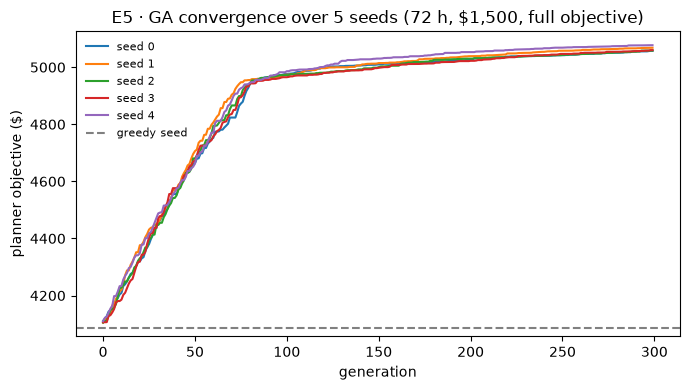

In [5]:
problem = build_problem(options, cohorts, week)
seed = greedy_genes(problem, options, week)
runs = Parallel(n_jobs=N_JOBS)(
    delayed(run_ga)(problem, week, seed, BETA, DECAY, seed=s) for s in range(5)
)
finals = pd.Series(
    [objective(problem, chosen(problem, g)) for g, _, _ in runs], name="final"
)
greedy_value = objective(problem, chosen(problem, seed))
picks = [set(chosen(problem, g)) for g, _, _ in runs]
overlap = np.mean(
    [len(a & b) / len(a | b) for i, a in enumerate(picks) for b in picks[i + 1 :]]
)
print(
    f"greedy {greedy_value:,.0f}; GA over 5 seeds: mean {finals.mean():,.0f}, sd {finals.std():,.1f} "
    f"(cv {100 * finals.std() / finals.mean():.2f}%), range {finals.min():,.0f}–{finals.max():,.0f}; "
    f"plans overlap {100 * overlap:.0f}% (Jaccard)"
)
pd.DataFrame(
    {
        "seed": range(5),
        "final": finals,
        "generations": [len(l) for _, l, _ in runs],
        "seconds": [s for _, _, s in runs],
    }
).to_csv(RES / "e5_seed_stability.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 4))
for s, (_, log, _) in enumerate(runs):
    ax.plot(log["generation"], log["best"], label=f"seed {s}")
ax.axhline(greedy_value, color="grey", ls="--", label="greedy seed")
ax.set_xlabel("generation")
ax.set_ylabel("planner objective ($)")
ax.set_title("E5 · GA convergence over 5 seeds (72 h, $1,500, full objective)")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "e5_convergence.png")
plt.show()

## 6. Speed vs size

Random instances of 250 to 4,000 members. The GA runs alone so the timing is clean. PLAN targets: 2,000 members in under
30 s, 4,000 in at most 60 s.

**Look for:** time per generation growing about linearly with size, and whether the targets are met.

In [6]:
rows = []
for n in (250, 500, 1000, 2000, 4000):
    opts, coh, lim = random_instance(options, cohorts, n, week, seed=n)
    sized = build_problem(opts, coh, lim)
    genes, log, ga_secs = run_ga(
        sized, lim, greedy_genes(sized, opts, lim), BETA, DECAY, seed=0
    )  # alone: clean timing
    _, status, cp_secs = solve_linear(opts, lim)
    rows.append(
        {
            "members": n,
            "options": len(opts),
            "ga_seconds": ga_secs,
            "ga_generations": len(log),
            "seconds_per_generation": ga_secs / len(log),
            "cp_sat_linear_seconds": cp_secs,
            "cp_sat_status": status,
        }
    )
speed = pd.DataFrame(rows)
speed.round(3).to_csv(RES / "e5_speed.csv", index=False)
speed.round(2)

,members,options,ga_seconds,ga_generations,seconds_per_generation,cp_sat_linear_seconds,cp_sat_status
0,250,500,6.37,300,0.02,0.12,OPTIMAL
1,500,1002,9.46,300,0.03,0.42,OPTIMAL
2,1000,2028,15.95,300,0.05,0.72,OPTIMAL
3,2000,4148,29.12,300,0.10,2.98,OPTIMAL
4,4000,8008,58.20,300,0.19,5.73,OPTIMAL


## 7. Sensitivity to β (spillover) and d (diminishing returns)

The GA's gain over greedy on the planner's objective, 2 seeds per cell.

**Look for:** a positive gain in every cell, i.e. the GA's advantage does not depend on the assumed strengths.

In [7]:
grid = [(b, d) for b in (0.0, 0.5, 1.0) for d in (0.0, 0.02, 0.05)]
runs = Parallel(n_jobs=N_JOBS)(
    delayed(run_ga)(problem, week, seed, b, d, seed=s)
    for b, d in grid
    for s in range(2)
)
rows = []
for k, (b, d) in enumerate(grid):
    greedy_value = objective(problem, chosen(problem, seed), b, d)
    for s in range(2):
        genes = runs[2 * k + s][0]
        rows.append(
            {
                "beta": b,
                "decay": d,
                "seed": s,
                "greedy": greedy_value,
                "ga": objective(problem, chosen(problem, genes), b, d),
            }
        )
sensitivity = pd.DataFrame(rows)
sensitivity["ga_gain_%"] = 100 * (sensitivity["ga"] / sensitivity["greedy"] - 1)
sensitivity.round(3).to_csv(RES / "e5_sensitivity.csv", index=False)
sensitivity.groupby(["beta", "decay"])["ga_gain_%"].mean().unstack("decay").round(1)

decay,0.00,0.02,0.05
beta,,,
0.0,20.3,25.5,28.5
0.5,20.3,23.9,27.0
1.0,23.0,22.8,25.9


## 8. Ablation: what repair and greedy seeding contribute

Full GA vs the GA with penalties instead of repair vs the GA seeded with an empty plan instead of greedy; 3 seeds.

**Look for:** both ablations score lower; `violations` stays 0 (the penalty is high enough to keep plans feasible).

In [8]:
empty = np.zeros_like(seed)
variants = {
    "full GA": {},
    "no repair (penalties)": {"use_repair": False},
    "no greedy seeding": {"seed_genes": empty},
}
jobs = [(name, s) for name in variants for s in range(3)]
runs = Parallel(n_jobs=N_JOBS)(
    delayed(run_ga)(
        problem,
        week,
        variants[name].get("seed_genes", seed),
        BETA,
        DECAY,
        seed=s,
        **{k: v for k, v in variants[name].items() if k != "seed_genes"},
    )
    for name, s in jobs
)
rows = []
for (name, s), (genes, log, secs) in zip(jobs, runs):
    plan = options.iloc[chosen(problem, genes)]
    rows.append(
        {
            "variant": name,
            "seed": s,
            "objective": objective(problem, chosen(problem, genes)),
            "violations": len(violations(plan, options, week)),
            "generations": len(log),
            "seconds": secs,
        }
    )
ablation = pd.DataFrame(rows)
ablation.round(3).to_csv(RES / "e5_ablation.csv", index=False)
ablation.groupby("variant")[
    ["objective", "violations", "generations", "seconds"]
].mean().round(1)

,objective,violations,generations,seconds
variant,,,,
full GA,5061.4,0.0,300.0,25.1
no greedy seeding,4969.0,0.0,300.0,19.8
no repair (penalties),4888.7,0.0,300.0,19.9


## 9. Figure

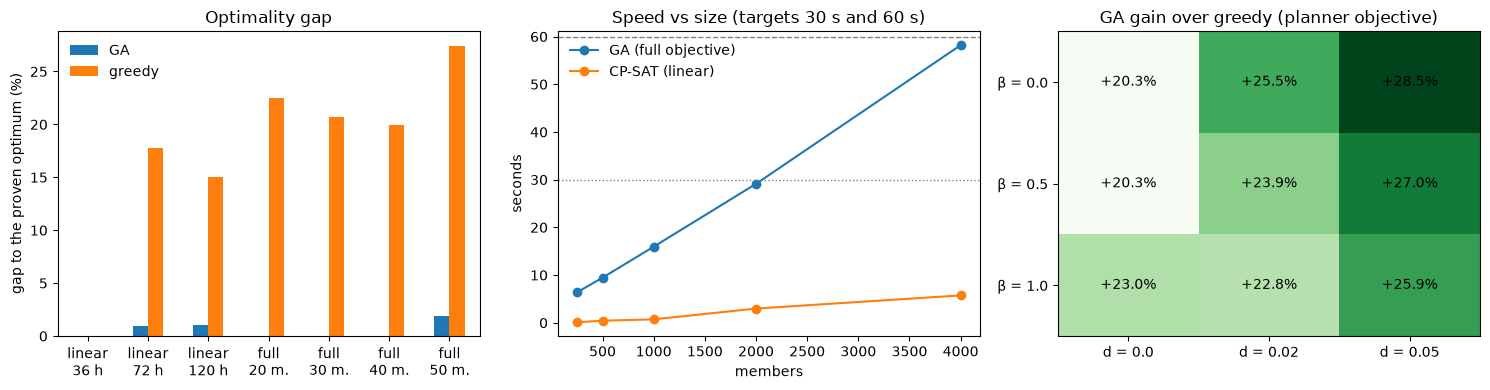

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ax = axes[0]
gaps = pd.DataFrame(
    {
        "GA": list(linear["ga_gap_%"])
        + list(full.groupby("members")["ga_gap_to_optimum_%"].mean().dropna()),
        "greedy": list(linear["greedy_gap_%"])
        + list(
            full[full["cp_sat_status"] == "OPTIMAL"]
            .groupby("members")["greedy_gap_%"]
            .mean()
        ),
    },
    index=[f"linear\n{h} h" for h, _ in SETTINGS]
    + [
        f"full\n{n} m."
        for n in full[full["cp_sat_status"] == "OPTIMAL"]["members"].unique()
    ],
)
gaps.plot.bar(ax=ax, rot=0)
ax.set_ylabel("gap to the proven optimum (%)")
ax.set_title("Optimality gap")
ax.legend(frameon=False)
ax = axes[1]
ax.plot(speed["members"], speed["ga_seconds"], marker="o", label="GA (full objective)")
ax.plot(
    speed["members"],
    speed["cp_sat_linear_seconds"],
    marker="o",
    label="CP-SAT (linear)",
)
ax.axhline(30, color="grey", ls=":", lw=1)
ax.axhline(60, color="grey", ls="--", lw=1)
ax.set_xlabel("members")
ax.set_ylabel("seconds")
ax.set_title("Speed vs size (targets 30 s and 60 s)")
ax.legend(frameon=False)
ax = axes[2]
heat = sensitivity.groupby(["beta", "decay"])["ga_gain_%"].mean().unstack("decay")
im = ax.imshow(heat.to_numpy(), cmap="Greens", aspect="auto")
ax.set_xticks(range(heat.shape[1]), [f"d = {d}" for d in heat.columns])
ax.set_yticks(range(heat.shape[0]), [f"β = {b}" for b in heat.index])
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"+{heat.iat[i, j]:.1f}%", ha="center", va="center")
ax.set_title("GA gain over greedy (planner objective)")
fig.tight_layout()
fig.savefig(FIG / "e5_optimiser.png")
plt.show()

## Findings (2026-10-20)

1. **Linear objective, full size:** CP-SAT proves the optimum in about 1 s. The GA is within 1.0% of it (0% at 36 h);
   greedy is 15–18% short at 72 and 120 h. Without the non-linear terms CP-SAT is the better tool, as PLAN drift item 9
   predicted.
2. **Full objective:** CP-SAT proves the optimum for all 12 instances of 20–50 members; the GA matches it at 20–40 members
   and is 1.9% short on average at 50, in 1–2 s, while CP-SAT's time rises from 0.02 s to 15 s. At 100 and 200 members
   CP-SAT proves nothing within 60 s and the GA's plan beats CP-SAT's best by 0.7–3.7% (CP-SAT's time-limited best varies between runs). Greedy is 19–27% short of the optimum.
3. **Stable:** 5 seeds end within 0.17% (cv) of each other; their plans share 77% of picks.
4. **Speed: at the edge of the targets.** 2,000 members took 29 s (target < 30 s) and 4,000 took 58 s (target ≤ 60 s)
   with the default 300 generations; on a busier machine an earlier run took 36 s and 74 s. Time per generation grows
   about linearly. The real gym (1,227 members with options) takes about 25 s; CP-SAT's linear model takes 6 s at 4,000.
5. **Robust to the assumptions:** the GA beats greedy by +20% to +29% on the planner's objective for every β ∈ {0, 0.5, 1}
   and d ∈ {0, 0.02, 0.05}; the gain grows with stronger diminishing returns.
6. **Both design choices help:** without greedy seeding the GA ends 1.8% lower; with penalties instead of repair, 3.4%
   lower. All plans stayed feasible.
7. These are gaps on the planner's **estimated** objective. On the truth, the GA's advantage depends on the estimates it
   is given (E4, `b_ga`; HANDOFFS #33).